# Bonus Lab · Vulkan GPU Memory (VRAM) Profiling & Out-of-Memory (OOM)

Every AI practitioner eventually hits the most famous error in GPU computing: **`OutOfDeviceMemory` (OOM)**.

In this hands-on bonus chapter, we'll tour every **VRAM profiling API** built into `vknumpy` (our Vulkan counterpart to NVIDIA RAPIDS `RMM` and PyTorch `torch.cuda.memory_*`), watch VRAM fill up to **2+ GB** and drop cleanly back to zero, spot hidden CPU↔GPU copies, and **safely trigger & catch a real Vulkan `ErrorOutOfDeviceMemory` error**!

### Quick Mental Math: How Much VRAM Does a Tensor Use?
Every standard `float32` number takes **4 bytes** in GPU memory:
- A `1,024 × 1,024` matrix = `1,048,576 × 4 bytes` = **`4.0 MB`**
- A `8,192 × 8,192` matrix = `67,108,864 × 4 bytes` = **`256.0 MB`**
- A 1-Billion parameter neural network in `float32` = **`4.0 GB`** just for weights — and **`~12–16 GB`** during `AdamW` training (weights + gradients + 2 optimizer moments + batch activations)!


In [1]:
import sys, time
from pathlib import Path
from IPython.display import display

_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "vknumpy").is_dir()), Path.cwd())
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import vknumpy as vnp
import vkplot

# 1. Inspect our Vulkan GPU & starting VRAM state
vnp.empty_cache()
vnp.reset_peak_memory_stats()

info = vnp.device_info()
mem  = vnp.memory_info()
print("Device Info :", info)
print(f"Live VRAM   : {vnp.memory_allocated() / (1024**2):.3f} MB")
print(f"Peak VRAM   : {vnp.max_memory_allocated() / (1024**2):.3f} MB")
print()
print(vnp.memory_summary())


Device Info : {'backend': 'ggml-vulkan', 'vulkan': True, 'name': 'AMD Custom GPU 0405 (RADV VANGOGH)', 'free_memory_mb': 11624.92, 'total_memory_mb': 12288.0, 'allocated_memory_mb': 0.0, 'peak_memory_mb': 0.0}
Live VRAM   : 0.000 MB
Peak VRAM   : 0.000 MB

=== Vulkan VRAM Summary (AMD Custom GPU 0405 (RADV VANGOGH)) ===
  Live Allocated :    0.000 MB (0 buffers)
  Peak Allocated :    0.000 MB
  Device Free    : 11624.92 MB / 12288.00 MB
  Alloc / Free   : 0 / 0
  H2D / D2H Copy :    0.000 MB up /    0.000 MB down


ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none


### Step 1 · Profiling Code Blocks & Spotting Accidental Host Copies (`vnp.profile_memory`)

The #1 silent performance killer in GPU code is accidentally copying tensors back and forth between CPU RAM (`Host`) and GPU VRAM (`Device`) — called **H2D** (*Host-to-Device*) and **D2H** (*Device-to-Host*) transfers.

Use `with vnp.profile_memory("label", verbose=True):` to measure **exact VRAM delta, peak VRAM, buffer allocation count, and H2D/D2H copy volume** for any block of code!


In [2]:
# Pre-allocate two 2048 x 2048 matrices in VRAM (16 MB each)
A = vnp.ones((2048, 2048))
B = vnp.ones((2048, 2048)) * 2.0

# Pattern 1 (FAST): Keep 100% of the math inside Vulkan VRAM -> 0.000 MB H2D/D2H!
with vnp.profile_memory("100% In-VRAM Math", verbose=True) as prof_gpu:
    C = (A + B) * 0.5
    D = vnp.sin(C) + vnp.cos(C)

# Pattern 2 (SLOW): Accidentally downloading a 16 MB tensor back to CPU!
with vnp.profile_memory("Accidental D2H Copy", verbose=True) as prof_cpu:
    _ = C.tolist()  # pulls 16 MB across the bus into Python lists!

print(f"\nIn-VRAM D2H traffic    : {prof_gpu['download_mb']:.3f} MB")
print(f"Accidental D2H traffic : {prof_cpu['download_mb']:.3f} MB  (avoid calling .tolist() inside training loops!)")

# Clean up and verify vnp.empty_cache()
del A, B, C, D
freed = vnp.empty_cache()
print(f"After del + empty_cache() -> Live VRAM: {vnp.memory_allocated() / (1024**2):.3f} MB")


[100% In-VRAM Math] VRAM delta=+32.000 MB | peak=96.000 MB | allocs=5 | H2D=0.000 MB | D2H=0.000 MB | 12.48 ms


[Accidental D2H Copy] VRAM delta=+0.000 MB | peak=64.000 MB | allocs=0 | H2D=0.000 MB | D2H=16.000 MB | 209.28 ms

In-VRAM D2H traffic    : 0.000 MB
Accidental D2H traffic : 16.000 MB  (avoid calling .tolist() inside training loops!)


After del + empty_cache() -> Live VRAM: 0.000 MB


### Step 2 · Filling Up VRAM: Watching Live vs. Peak Memory Climb to 2.0 GB & Recover

Let's allocate eight **256 MB** GPU tensors one by one (`256 MB → 2,048 MB`), watching `vnp.memory_allocated()` and `vnp.max_memory_allocated()` climb together — and then free them one by one to see **Live VRAM** drop back to `0 MB` while **Peak VRAM** remembers the high-water mark until we call `vnp.reset_peak_memory_stats()`.


  +Alloc #1 (+256 MB) | Live =   256.0 MB | Peak =   256.0 MB
  +Alloc #2 (+256 MB) | Live =   512.0 MB | Peak =   512.0 MB
  +Alloc #3 (+256 MB) | Live =   768.0 MB | Peak =   768.0 MB
  +Alloc #4 (+256 MB) | Live =  1024.0 MB | Peak =  1024.0 MB
  +Alloc #5 (+256 MB) | Live =  1280.0 MB | Peak =  1280.0 MB
  +Alloc #6 (+256 MB) | Live =  1536.0 MB | Peak =  1536.0 MB
  +Alloc #7 (+256 MB) | Live =  1792.0 MB | Peak =  1792.0 MB
  +Alloc #8 (+256 MB) | Live =  2048.0 MB | Peak =  2048.0 MB


  After freeing all 8 chunks -> Live = 0.0 MB | Peak (remembered) = 2048.0 MB
  After reset_peak_memory_stats() -> Peak = 0.0 MB


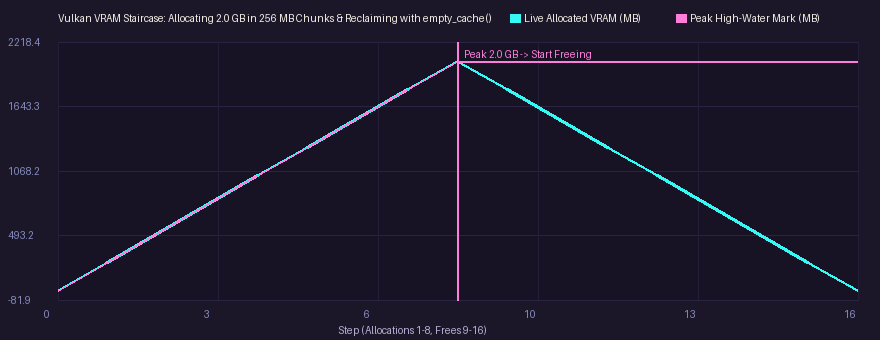

In [3]:
vnp.empty_cache()
vnp.reset_peak_memory_stats()

MB = 1024 * 1024
CHUNK_MB = 256
CHUNK_FLOATS = (CHUNK_MB * MB) // 4  # 67,108,864 float32s = exactly 256.0 MB

holders = []
steps, live_hist, peak_hist = [0], [vnp.memory_allocated() / MB], [vnp.max_memory_allocated() / MB]

# Phase A: Allocate 8 x 256 MB = 2,048 MB (2.0 GB) directly in Vulkan VRAM
for i in range(1, 9):
    holders.append(vnp.empty((CHUNK_FLOATS,)))
    steps.append(len(steps))
    live_hist.append(vnp.memory_allocated() / MB)
    peak_hist.append(vnp.max_memory_allocated() / MB)
    print(f"  +Alloc #{i} (+256 MB) | Live = {live_hist[-1]:7.1f} MB | Peak = {peak_hist[-1]:7.1f} MB")

# Phase B: Free tensors one by one -> Live drops to 0 MB while Peak stays at 2048 MB!
while holders:
    holders.pop()
    vnp.empty_cache()
    steps.append(len(steps))
    live_hist.append(vnp.memory_allocated() / MB)
    peak_hist.append(vnp.max_memory_allocated() / MB)

print(f"  After freeing all 8 chunks -> Live = {live_hist[-1]:.1f} MB | Peak (remembered) = {peak_hist[-1]:.1f} MB")
vnp.reset_peak_memory_stats()
print(f"  After reset_peak_memory_stats() -> Peak = {vnp.max_memory_allocated() / MB:.1f} MB")

display(vkplot.line_chart(
    [
        (steps, live_hist, "#36f9f6", 3, "Live Allocated VRAM (MB)"),
        (steps, peak_hist, "#ff7edb", 2, "Peak High-Water Mark (MB)"),
    ],
    vline=(8, "Peak 2.0 GB -> Start Freeing"),
    title="Vulkan VRAM Staircase: Allocating 2.0 GB in 256 MB Chunks & Reclaiming with empty_cache()",
    x_label="Step (Allocations 1-8, Frees 9-16)", width=880, height=340,
))


### Step 3 · Seeing the 4 GB BIOS Carve-Out vs. 12 GB Unified Memory (UMA + GTT) Live!

On an AMD APU like the Steam Deck (**Unified Memory**, `uma: 1`), the **BIOS `4 GB` UMA Frame Buffer** is only a *minimum reserved floor* — **not** a hard ceiling!

Watch what happens when we allocate **`512 MB`** GPU chunks all the way up to **`7.5 GB`** (with a safety guard so Linux `MemAvailable` never drops below `1.5 GB`):
- **0.5 GB → 3.5 GB:** Linux `MemAvailable` **barely moves** — every tensor fits inside the dedicated 4 GB BIOS VRAM carve-out!
- **4.0 GB → 7.5 GB:** The moment you cross the 4 GB BIOS boundary, `amdgpu` seamlessly spills into **GTT Unified RAM** (`~512 MB` per chunk from Linux RAM) — up to `12 GB` total!


  Chunk  1 ( 0.5 GB GPU) | Linux MemAvail =   7823 MB  [BIOS 4GB VRAM]
  Chunk  2 ( 1.0 GB GPU) | Linux MemAvail =   7823 MB  [BIOS 4GB VRAM]
  Chunk  3 ( 1.5 GB GPU) | Linux MemAvail =   7823 MB  [BIOS 4GB VRAM]
  Chunk  4 ( 2.0 GB GPU) | Linux MemAvail =   7823 MB  [BIOS 4GB VRAM]
  Chunk  5 ( 2.5 GB GPU) | Linux MemAvail =   7823 MB  [BIOS 4GB VRAM]
  Chunk  6 ( 3.0 GB GPU) | Linux MemAvail =   7823 MB  [BIOS 4GB VRAM]
  Chunk  7 ( 3.5 GB GPU) | Linux MemAvail =   7821 MB  [BIOS 4GB VRAM]


  Chunk  8 ( 4.0 GB GPU) | Linux MemAvail =   7305 MB  [GTT Unified RAM]
  Chunk  9 ( 4.5 GB GPU) | Linux MemAvail =   6793 MB  [GTT Unified RAM]
  Chunk 10 ( 5.0 GB GPU) | Linux MemAvail =   6293 MB  [GTT Unified RAM]


  Chunk 11 ( 5.5 GB GPU) | Linux MemAvail =   5793 MB  [GTT Unified RAM]
  Chunk 12 ( 6.0 GB GPU) | Linux MemAvail =   5305 MB  [GTT Unified RAM]


  Chunk 13 ( 6.5 GB GPU) | Linux MemAvail =   4741 MB  [GTT Unified RAM]
  Chunk 14 ( 7.0 GB GPU) | Linux MemAvail =   4289 MB  [GTT Unified RAM]


  Chunk 15 ( 7.5 GB GPU) | Linux MemAvail =   3730 MB  [GTT Unified RAM]


  Chunk 16 ( 8.0 GB GPU) | Linux MemAvail =   3147 MB  [GTT Unified RAM]
  Chunk 17 ( 8.5 GB GPU) | Linux MemAvail =   2686 MB  [GTT Unified RAM]


  Chunk 18 ( 9.0 GB GPU) | Linux MemAvail =   2259 MB  [GTT Unified RAM]


  Chunk 19 ( 9.5 GB GPU) | Linux MemAvail =   1654 MB  [GTT Unified RAM]

Freed all chunks cleanly -> Live VRAM: 0.0 MB | Linux MemAvail: 7780 MB


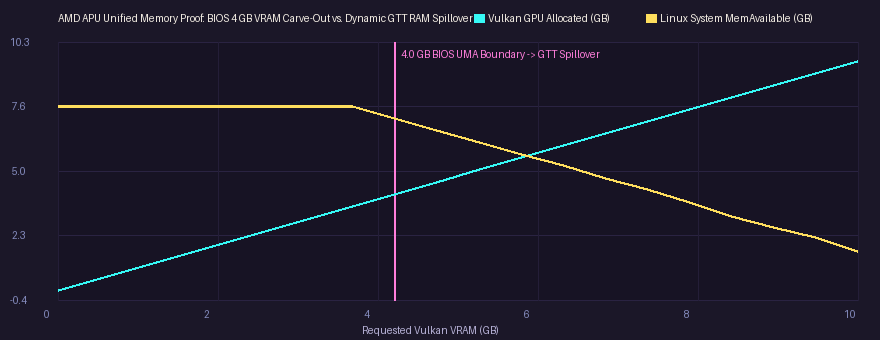

In [4]:
def sys_avail_mb():
    try:
        for line in open("/proc/meminfo"):
            if line.startswith("MemAvailable:"):
                return int(line.split()[1]) / 1024.0
    except OSError:
        pass
    return 0.0

vnp.empty_cache()
vnp.reset_peak_memory_stats()

MB = 1024 * 1024
STEP_MB = 512
STEP_FLOATS = (STEP_MB * MB) // 4

holders = []
xs_gb, gpu_live_gb, sys_free_gb = [0.0], [0.0], [sys_avail_mb() / 1024.0]

try:
    for i in range(1, 20):
        avail = sys_avail_mb()
        if avail > 0 and avail < 1500:
            print(f"  SAFETY STOP before chunk {i} ({i*0.5:.1f} GB): Linux MemAvailable={avail:.0f} MB (< 1,500 MB guard)")
            break
        holders.append(vnp.zeros((STEP_FLOATS,)))
        live_gb = vnp.memory_allocated() / (1024 ** 3)
        avail_after = sys_avail_mb()
        xs_gb.append(i * 0.5)
        gpu_live_gb.append(live_gb)
        sys_free_gb.append(avail_after / 1024.0)
        zone = "BIOS 4GB VRAM" if (avail_after > 0 and (sys_free_gb[0]*1024 - avail_after) < 250) else "GTT Unified RAM"
        print(f"  Chunk {i:2d} ({live_gb:4.1f} GB GPU) | Linux MemAvail = {avail_after:6.0f} MB  [{zone}]")
except MemoryError as e:
    print(f"  Hit Vulkan OOM at {len(holders)*0.5:.1f} GB: {e}")
finally:
    holders.clear()
    vnp.empty_cache()
    print(f"\nFreed all chunks cleanly -> Live VRAM: {vnp.memory_allocated() / MB:.1f} MB | Linux MemAvail: {sys_avail_mb():.0f} MB")

display(vkplot.line_chart(
    [
        (xs_gb, gpu_live_gb, "#36f9f6", 3, "Vulkan GPU Allocated (GB)"),
        (xs_gb, sys_free_gb, "#fede5d", 3, "Linux System MemAvailable (GB)"),
    ],
    vline=(4.0, "4.0 GB BIOS UMA Boundary -> GTT Spillover"),
    title="AMD APU Unified Memory Proof: BIOS 4 GB VRAM Carve-Out vs. Dynamic GTT RAM Spillover",
    x_label="Requested Vulkan VRAM (GB)", width=880, height=340,
))


### Step 4 · Pushing Past the 4 GB Single-Buffer Limit & Hitting Real Vulkan OOM

On Vulkan GPUs (like AMD RADV on Steam Deck), there are **two different memory limits** every developer should know:
1. **Per-Buffer Hardware Limit (`~4.0 GB` on Steam Deck):** A *single* `VkBuffer` larger than `4.0 GB` is rejected immediately with `ErrorOutOfDeviceMemory` — even when `10+ GB` of VRAM is free!
2. **Total Device Budget (`12.0 GB` UMA + GTT):** By splitting large data across **multiple buffers (`≤ 4 GB` each)** — the exact same trick `llama.cpp` uses to load 7B–8B LLMs layer-by-layer — you can easily sail past `4 GB` (up to `~9–11 GB` depending on free system RAM!).

*(Note: On Unified Memory / UMA systems, if multiple buffers exhaust both physical RAM and swap before Vulkan's 12 GB heap limit, the Linux OOM-killer will terminate the heaviest process — which is why our Step 3 loop used a `MemAvailable` safety guard!)*


In [5]:
GB = 1024 ** 3

# 1. Hit the 4 GB single-buffer wall (even though >10 GB is free!)
print("=== Test A: Single 4.5 GB Tensor (Hits Per-Buffer Vulkan Limit!) ===")
try:
    too_wide = vnp.empty((int(4.5 * GB) // 4,))
except MemoryError as err:
    print(f"  CAUGHT {type(err).__name__}: {err}")

# 2. Push PAST 4 GB cleanly by sharding into multiple <= 4 GB buffers (like LLM layers!)
print("\n=== Test B: Sharding 5.0 GB into Five 1.0 GB Buffers (Sails Past 4 GB!) ===")
shards = [vnp.empty((GB // 4,)) for _ in range(5)]
print(f"  SUCCESS! Allocated {len(shards)} x 1.0 GB shards -> Live VRAM = {vnp.memory_allocated() / GB:.2f} GB (past the 4 GB wall!)")
del shards
vnp.empty_cache()

# 3. Exceed Total Device VRAM (> 12 GB) -> Guaranteed Vulkan OOM!
mem = vnp.memory_info()
ask_gb = round((mem["total"] * 1.5) / GB, 1)
print(f"\n=== Test C: Requesting {ask_gb:.1f} GB (> {mem['total_mb']/1024:.1f} GB Total Device VRAM) ===")
try:
    too_big = vnp.empty((int(mem["total"] * 1.5) // 4,))
except MemoryError as err:
    print(f"  CAUGHT {type(err).__name__}: {err}")

# Verify the GPU is still 100% healthy & responsive right after OOM!
ok = vnp.ones((4, 4)) + 1.0
print(f"\nGPU recovery check after OOM: sum(ones(4,4) + 1) = {float(vnp.sum(ok)):.1f} (100% healthy!)")
del ok
vnp.empty_cache()
print()
print(vnp.memory_summary())


=== Test A: Single 4.5 GB Tensor (Hits Per-Buffer Vulkan Limit!) ===
  CAUGHT MemoryError: Failed to allocate 4831838208 bytes on Vulkan device: ggml_backend_buft_alloc_buffer failed

=== Test B: Sharding 5.0 GB into Five 1.0 GB Buffers (Sails Past 4 GB!) ===


  SUCCESS! Allocated 5 x 1.0 GB shards -> Live VRAM = 5.00 GB (past the 4 GB wall!)

=== Test C: Requesting 18.0 GB (> 12.0 GB Total Device VRAM) ===
  CAUGHT MemoryError: Failed to allocate 19327352832 bytes on Vulkan device: ggml_backend_buft_alloc_buffer failed


ggml_vulkan: Device memory allocation of size 4831838208 failed.
ggml_vulkan: Requested buffer size exceeds device buffer size limit: ErrorOutOfDeviceMemory
ggml_vulkan: Device memory allocation of size 19327352832 failed.
ggml_vulkan: Requested buffer size exceeds device buffer size limit: ErrorOutOfDeviceMemory



GPU recovery check after OOM: sum(ones(4,4) + 1) = 32.0 (100% healthy!)

=== Vulkan VRAM Summary (AMD Custom GPU 0405 (RADV VANGOGH)) ===
  Live Allocated :    0.000 MB (0 buffers)
  Peak Allocated : 9728.000 MB
  Device Free    : 11622.89 MB / 12288.00 MB
  Alloc / Free   : 43 / 43
  H2D / D2H Copy :    0.000 MB up /   16.000 MB down


### Step 5 · Out-of-Core GPU Streaming (`vpd.scan_csv` — Polars Streaming & Dask-cuDF Style!)

What if your CSV file is **15 GB or 50 GB** — way bigger than your GPU's VRAM?
- Loading it all at once with `vpd.read_csv()` would crash with OOM.
- Instead, **`vpd.scan_csv(path, vram_budget_mb="auto")`** streams the file through **multi-threaded C++ `pyarrow.csv` → Vulkan GPU chunks**, automatically picking a **high-occupancy VRAM budget** (`vpd.recommended_vram_budget_mb()`) so your GPU stays saturated and fast **without ever overflowing VRAM**!

Let's generate a **10,000,000-row** CSV on disk and race **Small (`16 MB`) vs. Medium (`128 MB`) vs. Auto High-Occupancy (`"auto"`)** VRAM budgets on a full GPU `filter -> with_columns -> groupby().agg()` pipeline!


Generated 10,000,000-row CSV (184.3 MB) in 0.20s
Auto-recommended high-occupancy VRAM budget on this GPU: 1536.0 MB



Streaming Mode                   | Chunks |  Peak VRAM |     Throughput |   Time
----------------------------------------------------------------------------------
Small Budget (16 MB)             |     29 |    17.6 MB |  1,308,245 r/s |  7.64s
Medium Budget (128 MB)           |      4 |   141.2 MB |  1,647,531 r/s |  6.07s
Auto High-Occupancy (1536 MB)    |      1 |   387.1 MB |  2,000,041 r/s |  5.00s

Exact Global GPU GroupBy Result across 10,000,000 streamed rows:


#,region,net_rev_sum,net_rev_mean,net_rev_count
0,east,"2,784,415,232","1,350.085","2,062,400"
1,north,"3,094,029,824","1,500.499","2,062,000"
2,south,"2,938,697,728","1,424.892","2,062,400"
3,west,"2,629,167,104","1,275.057","2,062,000"


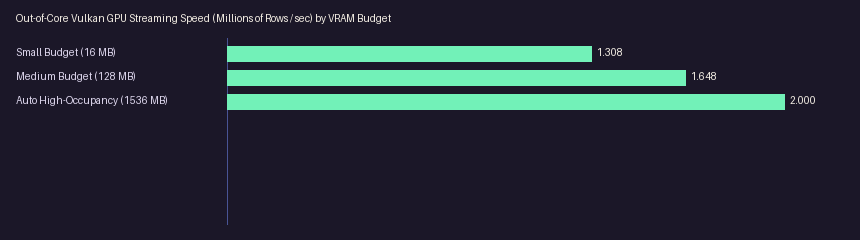

In [6]:
import vkpandas as vpd

# 1. Generate a 10,000,000-row CSV on disk (~85 MB) inside examples/data/ (cached once)
data_dir = Path(_root) / "examples" / "data"
data_dir.mkdir(parents=True, exist_ok=True)
big_csv = data_dir / "stream_bench_10m.csv"

if not big_csv.exists() or big_csv.stat().st_size < 150_000_000:
    t0 = time.perf_counter()
    block_rows = []
    regions = ("north", "south", "east", "west")
    for i in range(50_000):
        r = regions[i & 3]
        price = 15.0 + (i % 485) + 0.25 * (i % 7)
        qty = 1 + (i % 9)
        disc = 0.05 * (i % 4)
        block_rows.append(f"{r},{price:.2f},{qty},{disc:.2f}\n")
    block_str = "".join(block_rows)
    with open(big_csv, "w", encoding="utf-8") as f:
        f.write("region,price,qty,discount\n")
        for _ in range(200):  # 200 x 50,000 = 10,000,000 rows!
            f.write(block_str)
    print(f"Generated 10,000,000-row CSV ({big_csv.stat().st_size / (1024**2):.1f} MB) in {time.perf_counter()-t0:.2f}s")
else:
    print(f"Using cached 10,000,000-row CSV ({big_csv.stat().st_size / (1024**2):.1f} MB)")

auto_budget = vpd.recommended_vram_budget_mb()
print(f"Auto-recommended high-occupancy VRAM budget on this GPU: {auto_budget:.1f} MB\n")

def add_net_revenue(df):
    df["net_rev"] = df["price"] * df["qty"] * (1.0 - df["discount"])
    return df

# 2. Race Small vs Medium vs Auto High-Occupancy VRAM budgets on the exact same 10M-row pipeline!
bench_rows = []
final_gb = None
for label, budget in [
    ("Small Budget (16 MB)", 16.0),
    ("Medium Budget (128 MB)", 128.0),
    (f"Auto High-Occupancy ({auto_budget:.0f} MB)", "auto"),
]:
    sf = (
        vpd.scan_csv(big_csv, vram_budget_mb=budget)
        .filter(lambda df: df["price"] >= 100.0)
        .with_columns(add_net_revenue)
    )
    gb_res = sf.groupby("region").agg({"net_rev": ["sum", "mean", "count"]})
    st = sf.last_stats
    bench_rows.append((label, st))
    final_gb = gb_res

print(f"{'Streaming Mode':32s} | {'Chunks':>6s} | {'Peak VRAM':>10s} | {'Throughput':>14s} | {'Time':>6s}")
print("-" * 82)
for label, st in bench_rows:
    print(
        f"{label:32s} | {st['chunks']:6d} | {st['peak_vram_mb']:7.1f} MB | "
        f"{st['throughput_rows_s']:>10,d} r/s | {st['elapsed_s']:5.2f}s"
    )

print("\nExact Global GPU GroupBy Result across 10,000,000 streamed rows:")
display(final_gb)

display(vkplot.barh_chart(
    [lbl for lbl, _ in bench_rows],
    [st["throughput_rows_s"] / 1_000_000.0 for _, st in bench_rows],
    title="Out-of-Core Vulkan GPU Streaming Speed (Millions of Rows / sec) by VRAM Budget",
    width=860, height=240,
))


---
### How to Fix Real-World GPU Out-of-Memory (OOM) Errors
When you hit `MemoryError` / `ErrorOutOfDeviceMemory` while training a real neural network:
1. **Shrink `batch_size`** (e.g. `512 → 128 → 32`): Activations scale linearly with batch size — halving `batch_size` immediately cuts activation VRAM in half.
2. **Always wrap inference/evaluation in `with vt.no_grad():`**: Skipping autograd stops `vktorch` from storing intermediate tensors for backpropagation.
3. **Delete old tensors & call `vnp.empty_cache()`**: Drop references to temporary matrices or previous models before allocating the next one.
4. **Profile with `vnp.profile_memory()` & `vnp.memory_summary()`**: Pinpoint the exact line where `peak_mb` spikes or where accidental `D2H` copies happen!
